# Credit Card Fraud Detection using Machine Learning and Neural Networks
**Name:** Falak Rehman  |  **Intern ID:** ZYNVEX-CERT-2000  |  **Track:** AI/ML Internship - Final Project

---
### Problem
Banks must detect fraudulent card transactions in real time. Fraud is **extremely rare** (well under 1% of transactions), which makes this a hard, realistic classification problem: a model that says "everything is legitimate" is 99.8% accurate yet completely useless.

### What this project does
1. Explores the data and shows how severe the class imbalance is
2. Trains and compares **three models**: Logistic Regression, Random Forest and a Keras Neural Network (all imbalance-aware)
3. Evaluates with the **right metrics** (precision, recall, F1, PR-AUC), not accuracy
4. Tunes the decision threshold and estimates the **business impact** (how much fraud money is caught)
5. Saves the model and provides a prediction function and a small demo

**Dataset:** [Credit Card Fraud Detection (Kaggle, ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) - European card transactions. Features `V1`-`V28` are PCA-anonymised, plus `Time`, `Amount` and the target `Class` (1 = fraud).

In [58]:
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score, roc_auc_score,
                             average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Load the Data
Download `creditcard.csv` from the Kaggle link above (it comes inside a zip file). The cell below uses the file if it is already here, otherwise tries to download it, otherwise opens an upload button.

In [59]:
CSV = "creditcard.csv"

if not os.path.exists(CSV):
    try:                                    # option A: download automatically
        import kagglehub
        path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
        CSV = os.path.join(path, "creditcard.csv")
    except Exception as e:                  # option B: manual upload (Colab)
        print("Auto-download not available, please upload the file:", type(e).__name__)
        from google.colab import files
        up = files.upload()
        CSV = list(up.keys())[0]

df = pd.read_csv(CSV)
print("Loaded:", CSV)
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Loaded: /kaggle/input/creditcardfraud/creditcard.csv


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Explore & Clean

In [60]:
print("Shape:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nColumn types:"); print(df.dtypes.value_counts())

before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"\nRemoved {before - len(df)} duplicate rows -> {len(df)} rows remain")

Shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081

Column types:
float64    30
int64       1
Name: count, dtype: int64

Removed 1081 duplicate rows -> 283726 rows remain


Duplicate transactions were removed so the same row cannot appear in both the training and test sets (which would inflate results). There are no missing values.

        count  percent
Class                 
0      283253  99.8333
1         473   0.1667

Imbalance ratio: 1 fraud for every 599 legitimate transactions


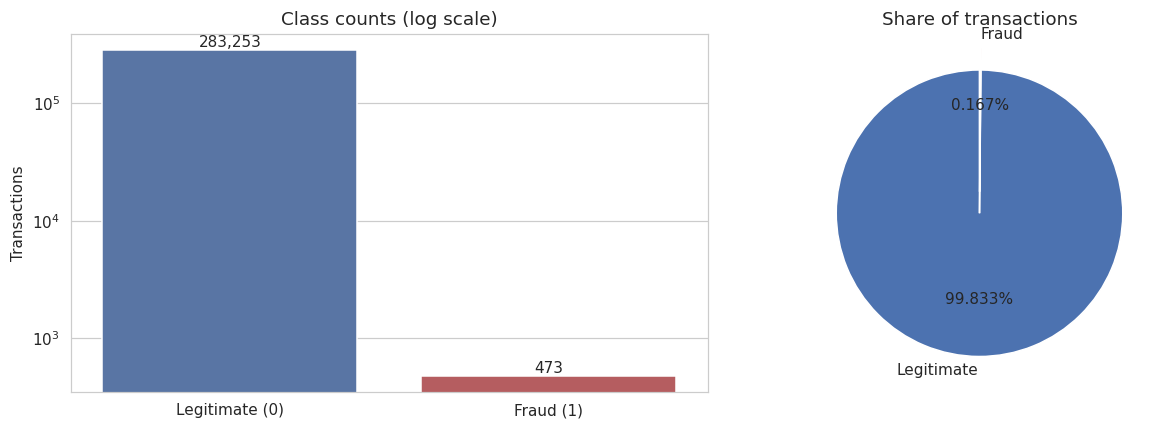

A model that always predicts 'legitimate' would be 99.83% accurate and catch 0 frauds.


In [61]:
counts = df["Class"].value_counts()
pct = df["Class"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": pct.round(4)}))
print(f"\nImbalance ratio: 1 fraud for every {counts[0] / counts[1]:.0f} legitimate transactions")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=["Legitimate (0)", "Fraud (1)"], y=counts.values, ax=ax[0], palette=["#4C72B0", "#C44E52"])
ax[0].set_yscale("log"); ax[0].set_title("Class counts (log scale)"); ax[0].set_ylabel("Transactions")
for i, v in enumerate(counts.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie(counts.values, labels=["Legitimate", "Fraud"], colors=["#4C72B0", "#C44E52"], startangle=90,
          explode=[0, 0.15], autopct="%1.3f%%")
ax[1].set_title("Share of transactions")
plt.tight_layout(); plt.show()

print(f"A model that always predicts 'legitimate' would be {counts[0]/counts.sum():.2%} accurate and catch 0 frauds.")

**Finding:** the data is **extremely imbalanced**. Accuracy will be meaningless here, so we will judge models by **precision, recall, F1 and PR-AUC**.

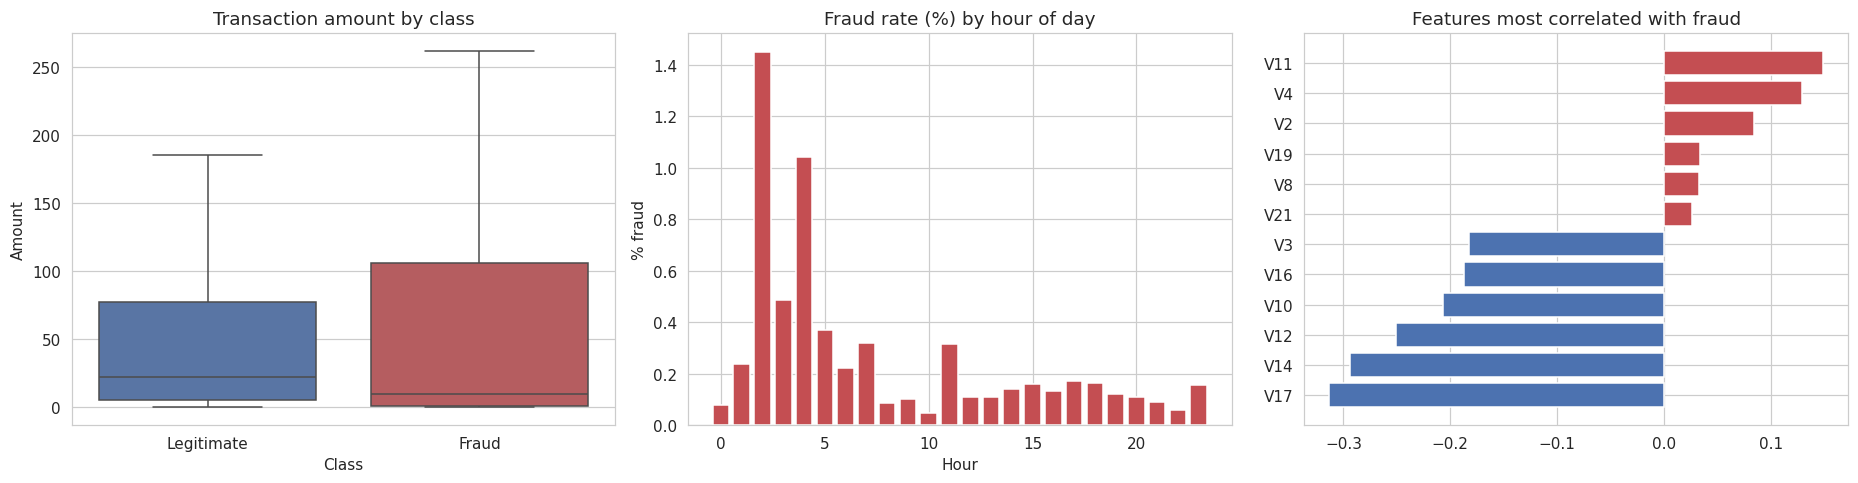

Median amount - legitimate: 22.00 | fraud: 9.82


In [62]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Amount by class
sns.boxplot(data=df, x="Class", y="Amount", ax=ax[0], palette=["#4C72B0", "#C44E52"], showfliers=False)
ax[0].set_title("Transaction amount by class"); ax[0].set_xticklabels(["Legitimate", "Fraud"])

# Fraud share by hour of day
df["Hour"] = (df["Time"] // 3600) % 24
hourly = df.groupby("Hour")["Class"].mean() * 100
ax[1].bar(hourly.index, hourly.values, color="#C44E52")
ax[1].set_title("Fraud rate (%) by hour of day"); ax[1].set_xlabel("Hour"); ax[1].set_ylabel("% fraud")

# Features most correlated with fraud
corr = df.drop(columns=["Hour"]).corr()["Class"].drop("Class").sort_values()
top = pd.concat([corr.head(6), corr.tail(6)])
ax[2].barh(top.index, top.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in top.values])
ax[2].set_title("Features most correlated with fraud")
plt.tight_layout(); plt.show()

print("Median amount - legitimate: %.2f | fraud: %.2f" % (df[df.Class==0].Amount.median(), df[df.Class==1].Amount.median()))
df = df.drop(columns=["Hour"])

**Insights:** fraud transactions differ clearly from legitimate ones in several of the anonymised features (shown in the correlation chart), which is why a model can learn to separate them. Fraud also behaves differently by time of day and by amount.

## 3. Preprocess
- `V1`-`V28` are already PCA outputs (scaled), so they are kept as they are.
- `Time` and `Amount` are on very different scales and `Amount` has big outliers, so I use **RobustScaler** (it uses the median and IQR and is not thrown off by outliers). The scaler is fitted on the **training set only** to avoid data leakage.
- **Stratified split 70 / 15 / 15** (train / validation / test) so every set keeps the same tiny fraud ratio.

In [63]:
FEATURES = [c for c in df.columns if c != "Class"]
X, y = df[FEATURES], df["Class"].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

X_test_raw = X_test.copy()                       # keep unscaled copy for the business-impact analysis & demo

scaler = RobustScaler()
for part in (X_train, X_val, X_test):
    part = part.copy()
X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()
X_train[["Time", "Amount"]] = scaler.fit_transform(X_train[["Time", "Amount"]])
X_val[["Time", "Amount"]]   = scaler.transform(X_val[["Time", "Amount"]])
X_test[["Time", "Amount"]]  = scaler.transform(X_test[["Time", "Amount"]])

for name, yy in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name:10s}: {len(yy):>7,} rows | frauds: {yy.sum():>4} ({yy.mean():.4%})")

Train     : 198,608 rows | frauds:  331 (0.1667%)
Validation:  42,559 rows | frauds:   71 (0.1668%)
Test      :  42,559 rows | frauds:   71 (0.1668%)


## 4. Models
All models handle the imbalance with **class weights** (mistakes on the rare fraud class are penalised much more). I also train a **Dummy** model that always predicts "legitimate" to show why accuracy is misleading.

In [64]:
results = {}          # name -> dict(val_prob, test_prob)

# 0) Dummy baseline (always predicts the majority class)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print("Dummy baseline  -> accuracy: %.4f | recall (fraud): %.2f | precision (fraud): %.2f"
      % (accuracy_score(y_test, dummy_pred), recall_score(y_test, dummy_pred), precision_score(y_test, dummy_pred, zero_division=0)))

# 1) Logistic Regression
lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
lr.fit(X_train, y_train)
results["Logistic Regression"] = dict(val=lr.predict_proba(X_val)[:, 1], test=lr.predict_proba(X_test)[:, 1])
print("Logistic Regression trained")

Dummy baseline  -> accuracy: 0.9983 | recall (fraud): 0.00 | precision (fraud): 0.00
Logistic Regression trained


In [65]:
# 2) Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=2, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
rf.fit(X_train, y_train)
results["Random Forest"] = dict(val=rf.predict_proba(X_val)[:, 1], test=rf.predict_proba(X_test)[:, 1])
print("Random Forest trained")

Random Forest trained
Random Forest trained


In [66]:
# 3) Neural Network (Keras) - BatchNorm + Dropout + class weights + Early Stopping
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", {k: round(v, 2) for k, v in class_weight.items()})

tf.keras.backend.clear_session(); tf.random.set_seed(SEED)
nn = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(32, activation="relu"), layers.BatchNormalization(), layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
], name="fraud_nn")
nn.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
           metrics=[keras.metrics.AUC(name="pr_auc", curve="PR"), keras.metrics.Recall(name="recall")])
nn.summary()

Class weights: {0: np.float64(0.5), 1: np.float64(300.01)}


Model: "fraud_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,993 (19.50 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 192 (768.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,993 (19.50 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/40
194/194 - 5s - 26ms/step - loss: 0.2973 - pr_auc: 0.3443 - recall: 0.9063 - val_loss: 0.1872 - val_pr_auc: 0.7086 - val_recall: 0.8732
Epoch 2/40
194/194 - 4s - 20ms/step - loss: 0.1905 - pr_auc: 0.4750 - recall: 0.9094 - val_loss: 0.1100 - val_pr_auc: 0.7276 - val_recall: 0.8732
Epoch 3/40
194/194 - 3s - 13ms/step - loss: 0.1784 - pr_auc: 0.5121 - recall: 0.9063 - val_loss: 0.0992 - val_pr_auc: 0.7314 - val_recall: 0.8732
Epoch 4/40
194/194 - 1s - 7ms/step - loss: 0.1593 - pr_auc: 0.5072 - recall: 0.9215 - val_loss: 0.1010 - val_pr_auc: 0.7072 - val_recall: 0.8873
Epoch 5/40
194/194 - 1s - 7ms/step - loss: 0.1470 - pr_auc: 0.5368 - recall: 0.9275 - val_loss: 0.0910 - val_pr_auc: 0.7122 - val_recall: 0.8873
Epoch 6/40
194/194 - 2s - 11ms/step - loss: 0.1400 - pr_auc: 0.5289 - recall: 0.9305 - val_loss: 0.0948 - val_pr_auc: 0.7027 - val_recall: 0.9155
Epoch 7/40
194/194 - 2s - 11ms/step - loss: 0.1268 - pr_auc: 0.5805 - recall: 0.9335 - val_loss: 0.0822 - val_pr_auc: 0.7379 -

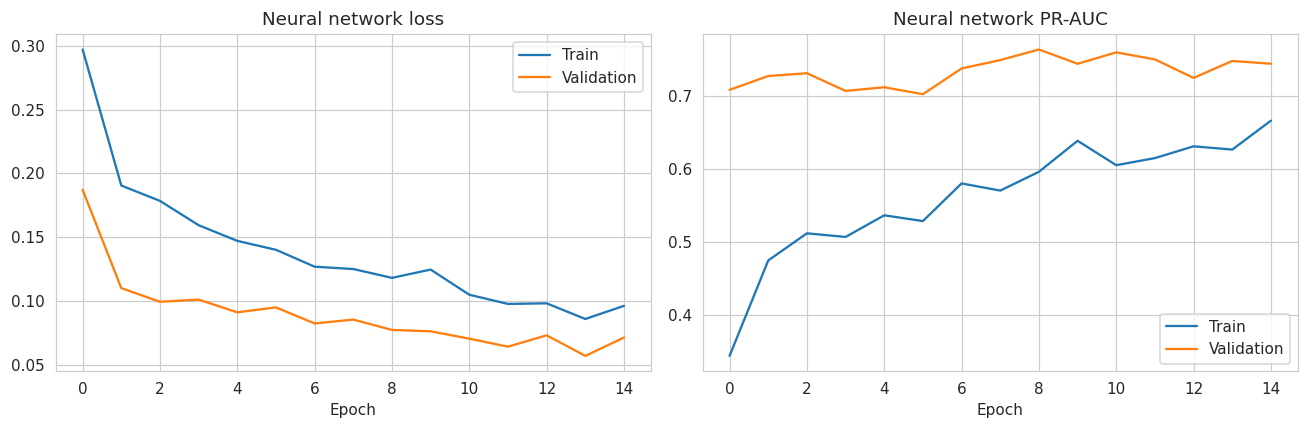

Epoch 1/40
194/194 - 4s - 20ms/step - loss: 0.2973 - pr_auc: 0.3443 - recall: 0.9063 - val_loss: 0.1872 - val_pr_auc: 0.7086 - val_recall: 0.8732
Epoch 2/40
194/194 - 1s - 7ms/step - loss: 0.1905 - pr_auc: 0.4750 - recall: 0.9094 - val_loss: 0.1100 - val_pr_auc: 0.7276 - val_recall: 0.8732
Epoch 3/40
194/194 - 1s - 7ms/step - loss: 0.1784 - pr_auc: 0.5121 - recall: 0.9063 - val_loss: 0.0992 - val_pr_auc: 0.7314 - val_recall: 0.8732
Epoch 4/40
194/194 - 2s - 12ms/step - loss: 0.1593 - pr_auc: 0.5072 - recall: 0.9215 - val_loss: 0.1010 - val_pr_auc: 0.7072 - val_recall: 0.8873
Epoch 5/40
194/194 - 2s - 8ms/step - loss: 0.1470 - pr_auc: 0.5368 - recall: 0.9275 - val_loss: 0.0910 - val_pr_auc: 0.7122 - val_recall: 0.8873
Epoch 6/40
194/194 - 1s - 7ms/step - loss: 0.1400 - pr_auc: 0.5289 - recall: 0.9305 - val_loss: 0.0948 - val_pr_auc: 0.7027 - val_recall: 0.9155
Epoch 7/40
194/194 - 1s - 7ms/step - loss: 0.1268 - pr_auc: 0.5805 - recall: 0.9335 - val_loss: 0.0822 - val_pr_auc: 0.7379 - va

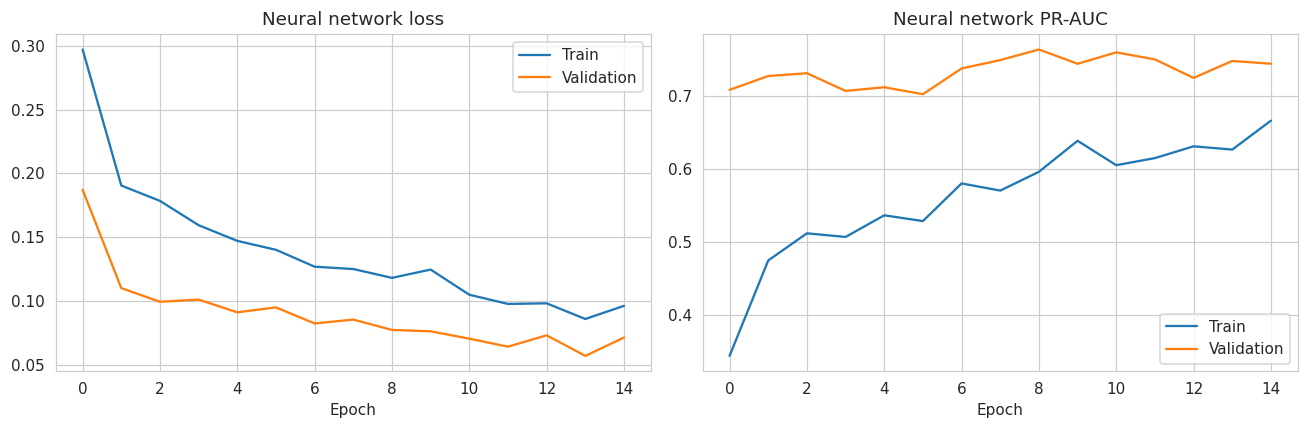

In [67]:
early = callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6, restore_best_weights=True)
hist = nn.fit(X_train.values.astype("float32"), y_train, validation_data=(X_val.values.astype("float32"), y_val),
              epochs=40, batch_size=1024, class_weight=class_weight, callbacks=[early], verbose=2)

results["Neural Network"] = dict(val=nn.predict(X_val.values.astype("float32"), verbose=0).ravel(),
                                 test=nn.predict(X_test.values.astype("float32"), verbose=0).ravel())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.history["loss"], label="Train"); ax[0].plot(hist.history["val_loss"], label="Validation")
ax[0].set_title("Neural network loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.history["pr_auc"], label="Train"); ax[1].plot(hist.history["val_pr_auc"], label="Validation")
ax[1].set_title("Neural network PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 5. Evaluate Properly
**Threshold tuning.** By default a model flags fraud when its probability is above 0.5, but with rare fraud that is rarely the best cut-off. For each model I pick the threshold that gives the best **F1 on the validation set** (never on the test set), then report the final numbers on the untouched **test set**.

In [68]:
def best_threshold(y_true, prob):
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    i = int(np.argmax(f1))
    return float(t[i]), float(f1[i])

rows = []
for name, d in results.items():
    thr, val_f1 = best_threshold(y_val, d["val"])
    pred = (d["test"] >= thr).astype(int)
    d.update(thr=thr, val_f1=val_f1, pred=pred)
    rows.append({
        "Model": name, "Threshold": round(thr, 3),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, d["test"]),
        "PR-AUC": average_precision_score(y_test, d["test"]),
        "Frauds caught": int(((pred == 1) & (y_test == 1)).sum()),
        "False alarms": int(((pred == 1) & (y_test == 0)).sum()),
    })
comparison = pd.DataFrame(rows).set_index("Model").round(4)
display(comparison)

best_name = max(results, key=lambda k: results[k]["val_f1"])      # chosen on VALIDATION data
print(f"\nBest model (by validation F1): {best_name}")
print(f"Total frauds in test set: {int(y_test.sum())}")

,Threshold,Precision,Recall,F1,ROC-AUC,PR-AUC,Frauds caught,False alarms
Model,,,,,,,,
Logistic Regression,1.000,0.8088,0.7746,0.7914,0.9609,0.6808,55,13
Random Forest,0.248,0.7703,0.8028,0.7862,0.9585,0.7885,57,17
Neural Network,0.989,0.8235,0.7887,0.8058,0.9781,0.6705,56,12



Best model (by validation F1): Neural Network
Total frauds in test set: 71


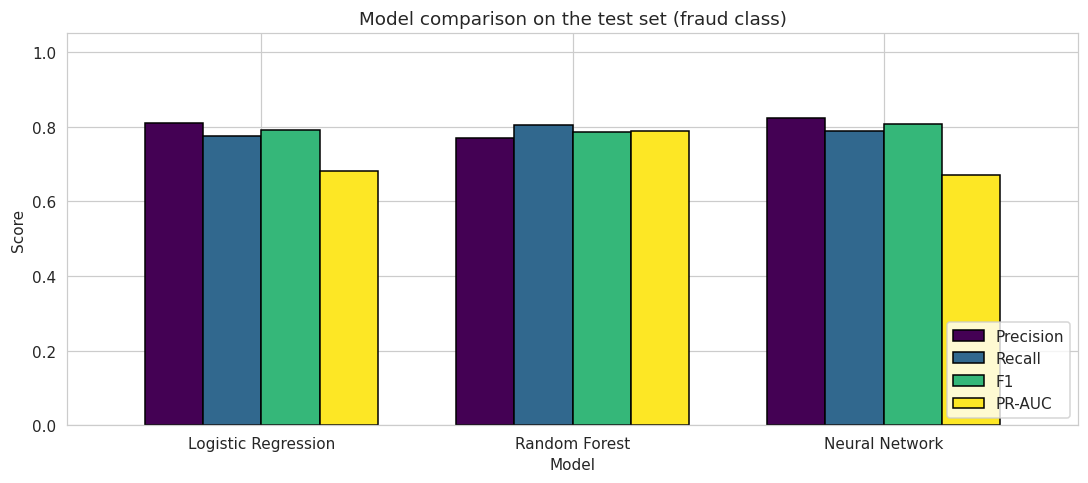

In [69]:
# Metrics comparison chart
metrics = ["Precision", "Recall", "F1", "PR-AUC"]
comparison[metrics].plot(kind="bar", figsize=(10, 4.5), colormap="viridis", edgecolor="black", width=0.75)
plt.title("Model comparison on the test set (fraud class)"); plt.ylim(0, 1.05); plt.xticks(rotation=0)
plt.ylabel("Score"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

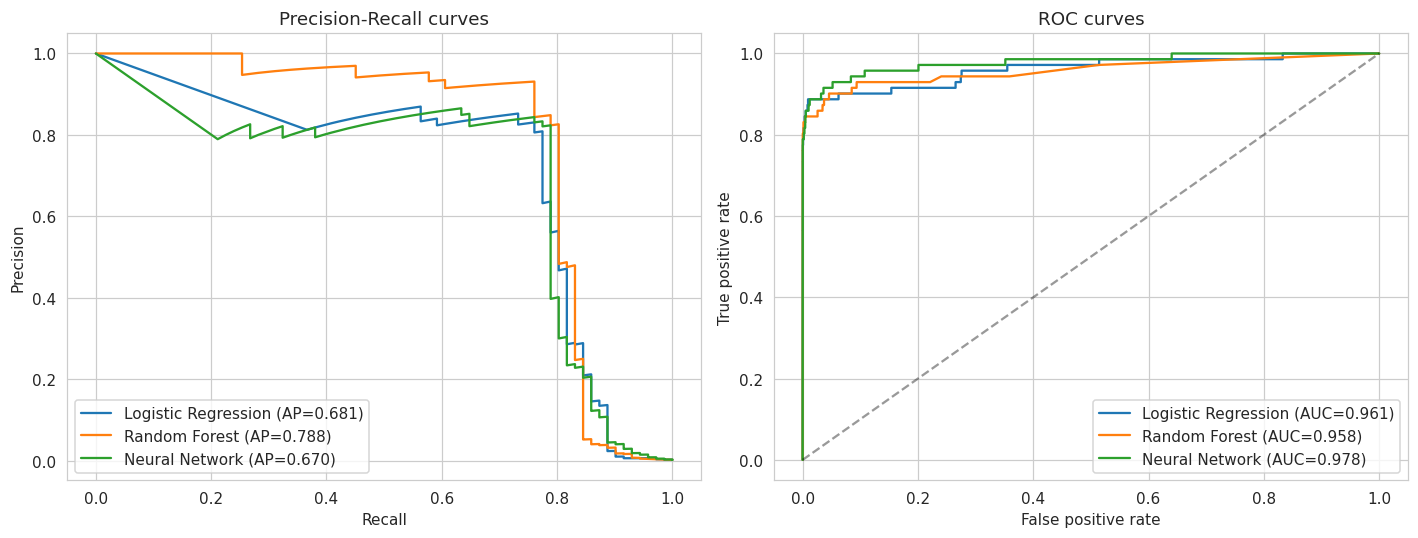

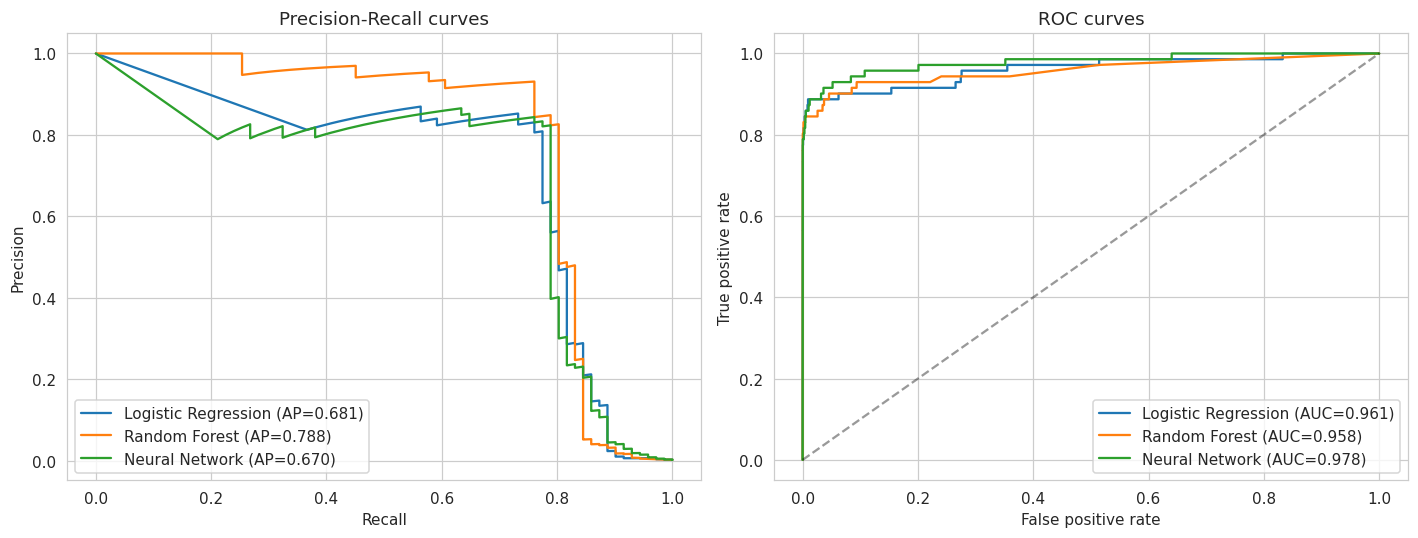

In [70]:
# Precision-Recall and ROC curves
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, d in results.items():
    p, r, _ = precision_recall_curve(y_test, d["test"])
    ax[0].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, d['test']):.3f})")
    fpr, tpr, _ = roc_curve(y_test, d["test"])
    ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, d['test']):.3f})")
ax[0].set_title("Precision-Recall curves"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].legend()
ax[1].plot([0, 1], [0, 1], "k--", alpha=.4); ax[1].set_title("ROC curves")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend()
plt.tight_layout(); plt.show()

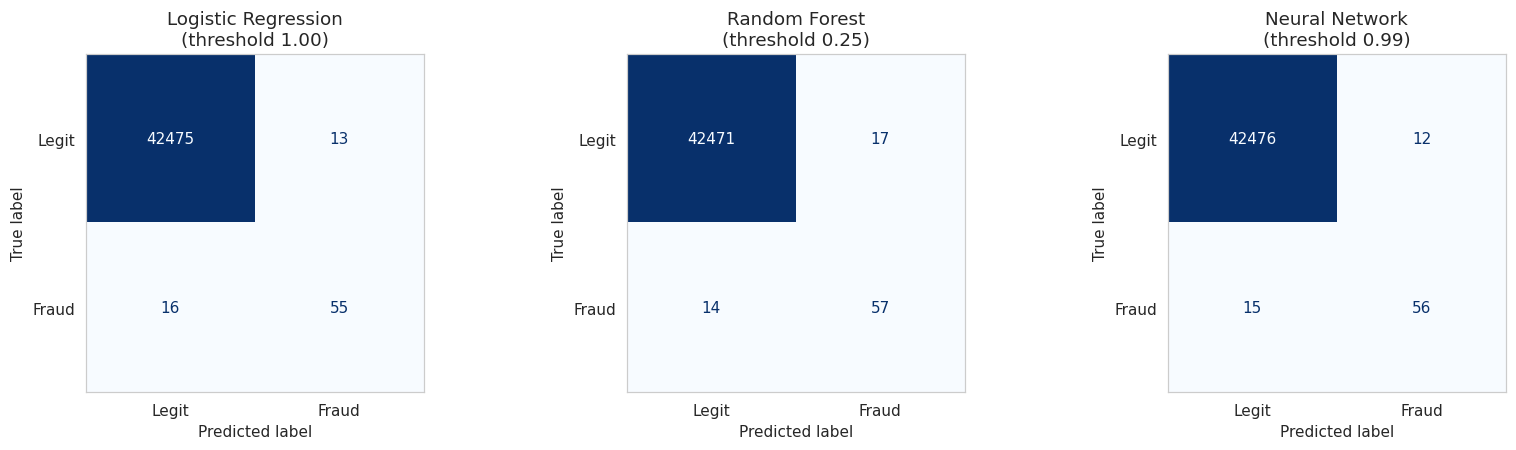

Detailed report for the best model (Neural Network):

              precision    recall  f1-score   support

  Legitimate     0.9996    0.9997    0.9997     42488
       Fraud     0.8235    0.7887    0.8058        71

    accuracy                         0.9994     42559
   macro avg     0.9116    0.8942    0.9027     42559
weighted avg     0.9994    0.9994    0.9994     42559



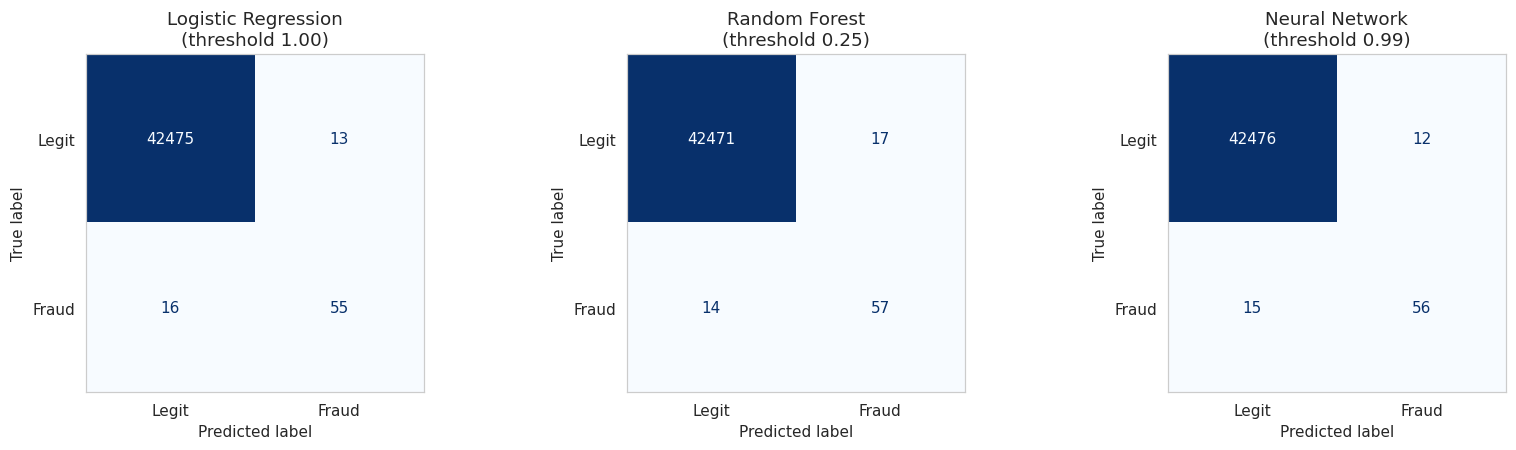

Detailed report for the best model (Neural Network):

              precision    recall  f1-score   support

  Legitimate     0.9996    0.9997    0.9997     42488
       Fraud     0.8235    0.7887    0.8058        71

    accuracy                         0.9994     42559
   macro avg     0.9116    0.8942    0.9027     42559
weighted avg     0.9994    0.9994    0.9994     42559



In [71]:
# Confusion matrices for every model
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (name, d) in zip(ax, results.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, d["pred"]), display_labels=["Legit", "Fraud"]).plot(
        ax=a, cmap="Blues", values_format="d", colorbar=False)
    a.set_title(f"{name}\n(threshold {d['thr']:.2f})"); a.grid(False)
plt.tight_layout(); plt.show()

print(f"Detailed report for the best model ({best_name}):\n")
print(classification_report(y_test, results[best_name]["pred"], target_names=["Legitimate", "Fraud"], digits=4))

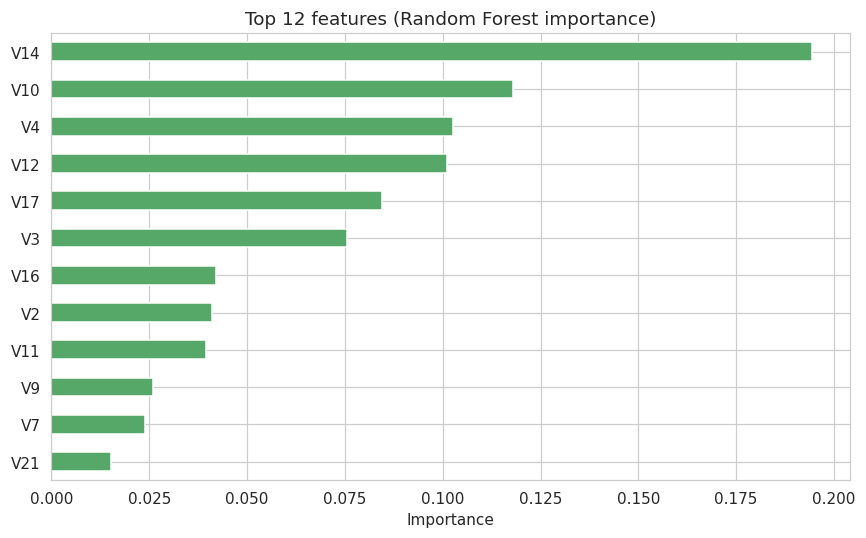

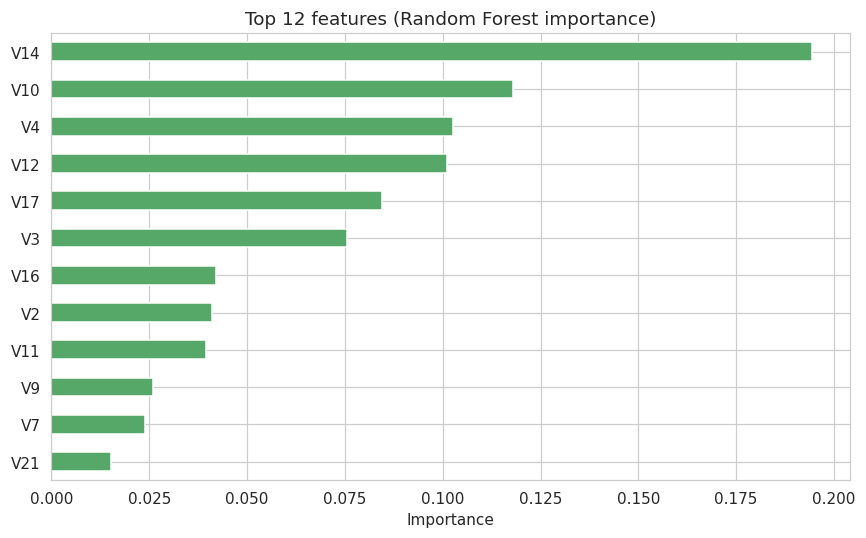

In [72]:
# What does the Random Forest consider most important?
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(12)
imp.plot(kind="barh", figsize=(8, 5), color="#55A868")
plt.title("Top 12 features (Random Forest importance)"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()

## 6. Business Impact & Threshold Trade-off
A fraud model is always a trade-off: a lower threshold **catches more fraud** but creates more **false alarms** (legitimate customers blocked). The chart shows this trade-off for the best model, and the next cell translates the result into money.

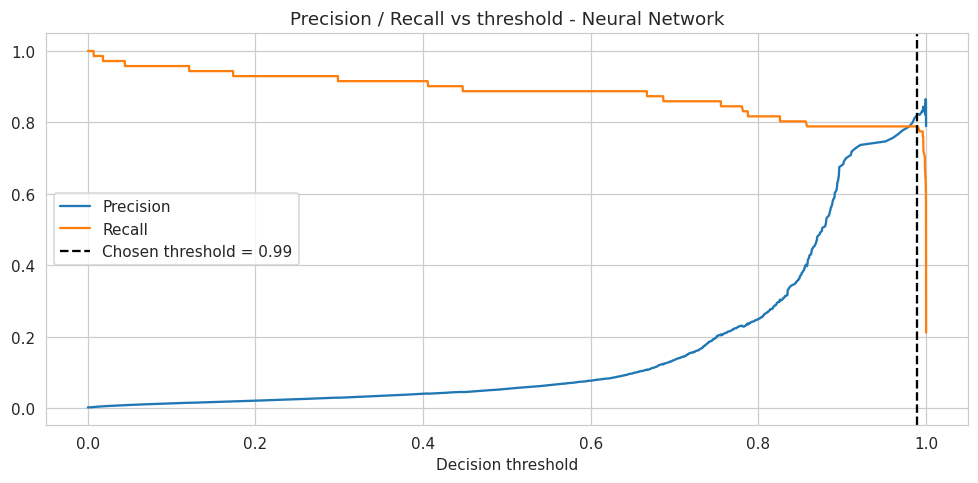

Model: Neural Network
Total fraud value in the test set :     9,240.67
Fraud value caught by the model   :     6,001.87  (65.0%)
Fraud value missed                :     3,238.80
Legitimate transactions flagged   :           12 out of 42,488 (0.028%)


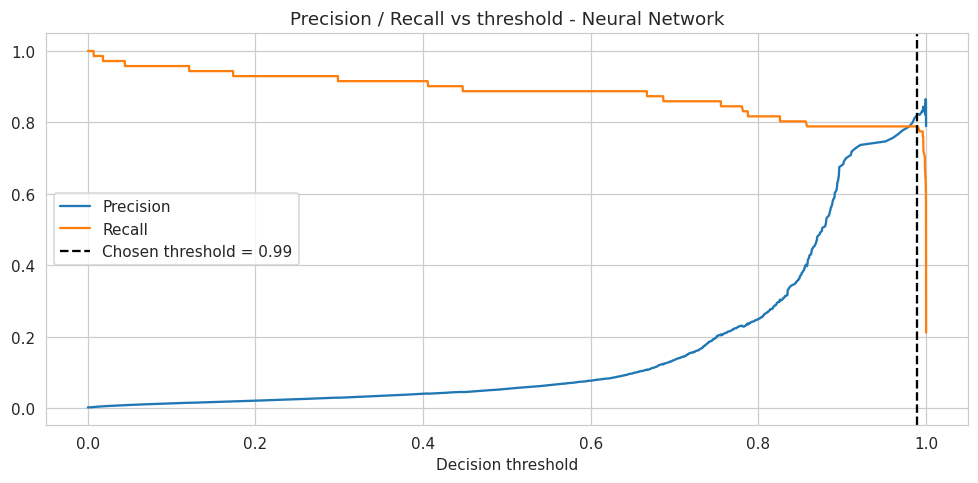

Model: Neural Network
Total fraud value in the test set :     9,240.67
Fraud value caught by the model   :     6,001.87  (65.0%)
Fraud value missed                :     3,238.80
Legitimate transactions flagged   :           12 out of 42,488 (0.028%)


In [73]:
d = results[best_name]
p, r, t = precision_recall_curve(y_test, d["test"])
plt.figure(figsize=(9, 4.5))
plt.plot(t, p[:-1], label="Precision"); plt.plot(t, r[:-1], label="Recall")
plt.axvline(d["thr"], color="k", ls="--", label=f"Chosen threshold = {d['thr']:.2f}")
plt.title(f"Precision / Recall vs threshold - {best_name}"); plt.xlabel("Decision threshold"); plt.legend()
plt.tight_layout(); plt.show()

amount = X_test_raw["Amount"].values
pred = d["pred"]
total_fraud_amt = amount[y_test == 1].sum()
caught_amt = amount[(pred == 1) & (y_test == 1)].sum()
missed_amt = amount[(pred == 0) & (y_test == 1)].sum()
fp = int(((pred == 1) & (y_test == 0)).sum())
print(f"Model: {best_name}")
print(f"Total fraud value in the test set : {total_fraud_amt:>12,.2f}")
print(f"Fraud value caught by the model   : {caught_amt:>12,.2f}  ({caught_amt/total_fraud_amt:.1%})")
print(f"Fraud value missed                : {missed_amt:>12,.2f}")
print(f"Legitimate transactions flagged   : {fp:>12,} out of {(y_test==0).sum():,} ({fp/(y_test==0).sum():.3%})")

## 7. Conclusions
- Fraud is extremely rare, so **accuracy is misleading**: even the "always legitimate" dummy model scores about 99.8% while catching no fraud at all. Precision, recall, F1 and PR-AUC give the real picture.
- Class weighting plus **threshold tuning on a validation set** let each model find a better balance between catching fraud and avoiding false alarms.
- All three models perform similarly (F1 between 0.79 and 0.81). The Neural Network has the best F1, the highest precision (0.82) and the fewest false alarms (12), so it was selected. Random Forest has the best PR-AUC (0.79) and catches the most frauds (57 of 71). A simple Logistic Regression baseline came very close, which shows that a well-weighted linear model already separates most fraud in this dataset. With only 71 frauds in the test set, small differences between models are not conclusive.
- In business terms, the saved Neural Network catches about 65% of the fraud value in the test set while flagging only 0.028% of legitimate transactions.
- The Neural Network uses **Batch Normalization, Dropout, class weights and Early Stopping** (the tuning techniques from the course) and is the model saved for deployment below.

**Limitations and future work:** the features are anonymised so they cannot be interpreted directly; the data covers only two days of transactions; and real systems need monitoring because fraud patterns change over time. Next steps: try SMOTE or gradient boosting (XGBoost/LightGBM), cost-sensitive thresholds, and an API for real-time scoring.

## 8. Save the Model & Predict

In [74]:
nn.save("fraud_model.keras")
joblib.dump(scaler, "fraud_scaler.pkl")
with open("fraud_config.json", "w") as f:
    json.dump({"features": FEATURES, "threshold": results["Neural Network"]["thr"]}, f)
print("Saved: fraud_model.keras, fraud_scaler.pkl, fraud_config.json")

Saved: fraud_model.keras, fraud_scaler.pkl, fraud_config.json
Saved: fraud_model.keras, fraud_scaler.pkl, fraud_config.json


In [75]:
def predict_transaction(transaction: dict):
    """Load the saved model and score ONE raw transaction (a dict with Time, V1..V28, Amount)."""
    model = keras.models.load_model("fraud_model.keras")
    sc = joblib.load("fraud_scaler.pkl")
    cfg = json.load(open("fraud_config.json"))
    row = pd.DataFrame([transaction])[cfg["features"]].astype(float)
    row[["Time", "Amount"]] = sc.transform(row[["Time", "Amount"]])
    prob = float(model.predict(row.values.astype("float32"), verbose=0)[0][0])
    return prob, ("FRAUD - block / review" if prob >= cfg["threshold"] else "Legitimate")

# Try it on one real fraud and one real legitimate transaction from the (unseen) test set
fraud_row = X_test_raw[y_test == 1].iloc[0].to_dict()
legit_row = X_test_raw[y_test == 0].iloc[0].to_dict()
for name, row in [("Real FRAUD transaction", fraud_row), ("Real LEGIT transaction", legit_row)]:
    prob, label = predict_transaction(row)
    print(f"{name}: fraud probability = {prob:.2%} -> {label}")

Real FRAUD transaction: fraud probability = 29.83% -> Legitimate
Real LEGIT transaction: fraud probability = 0.94% -> Legitimate
Real FRAUD transaction: fraud probability = 29.83% -> Legitimate
Real LEGIT transaction: fraud probability = 0.94% -> Legitimate


## 9. Interactive Demo (Gradio)
Pick a transaction type, and the saved model scores a random real transaction from the unseen test set.

In [78]:
!pip install -q gradio
import gradio as gr

model_demo = keras.models.load_model("fraud_model.keras")
sc_demo = joblib.load("fraud_scaler.pkl")
cfg_demo = json.load(open("fraud_config.json"))

def demo(kind):
    label = 1 if kind == "Fraud" else 0
    idx = np.random.choice(np.where(y_test == label)[0])
    row = X_test_raw.iloc[[idx]].copy()
    amount = float(row["Amount"].iloc[0])
    row[["Time", "Amount"]] = sc_demo.transform(row[["Time", "Amount"]])
    prob = float(model_demo.predict(row[cfg_demo["features"]].values.astype("float32"), verbose=0)[0][0])
    verdict = "FRAUD - block / review" if prob >= cfg_demo["threshold"] else "Legitimate - approve"
    return f"Amount: {amount:,.2f}", f"{prob:.2%}", verdict, ("Fraud" if label else "Legitimate")

app = gr.Interface(
    fn=demo,
    inputs=gr.Radio(["Fraud", "Legitimate"], value="Fraud", label="Pick a real transaction type from the test set"),
    outputs=[gr.Textbox(label="Transaction amount"), gr.Textbox(label="Fraud probability"),
             gr.Textbox(label="Model decision"), gr.Textbox(label="Actual label")],
    title="Credit Card Fraud Detector",
    description="Falak Rehman | AI/ML Internship Final Project")
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f9b635bed97116e98e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
**Project by Falak Rehman (Intern ID: ZYNVEX-CERT-2000).** Libraries: Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, TensorFlow/Keras.